<a href="https://colab.research.google.com/github/thuongle825/Problem-Set-5/blob/main/Problem_Set_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 PS5: Right 93% of the Time

##The Mission

A lender's model flags loan applications likely to default. The vendor's one-page summary says 93% accuracy and the head of risk is ready to sign.

You pull the data and find that 93% of applications do not default. A model that approves everything would be right 93% of the time. The vendor's number is consistent with a model that has learned nothing at all — and it is also consistent with a good model. Nothing in the summary tells you which.

Your job is to find out, and then to answer the question the vendor did not ask: at what threshold should this thing actually decline an application? That is not a statistical question, and pretending it is has cost lenders a great deal of money.


## Setup

In [177]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

## Phase 1: Build the Baseline Nobody Built (15 pts)

### Step 1.1: The data (8 pts)

In [178]:
np. random.seed(42)
n = 6000

income = np.random.normal(60000, 20000, n).clip(15000)
dti = np.random.uniform(0.05, 0.6, n)
credit_history = np.random.uniform(1, 30, n)
prior_delinquencies = np.random.poisson(0.5,n)
loan_amount = np.random.uniform(5000, 50000, n)

noise1 = np.random.normal(0, 1, n)
noise2 = np.random.uniform(0, 1,n)
noise3 = np.random.randint(0,2, n)

In [179]:
log_odds = (-3.5 - 0.00004 * (income - 60000) + 5 * (dti - 0.33)
            - 0.05 * (credit_history - 15) + 0.6 * prior_delinquencies
            + 0.00002 * (loan_amount - 27500))

prob_default = 1 / (1 + np.exp(-log_odds))
default = np.random.binomial(1, prob_default)

df = pd. DataFrame ({"income": income, "dti": dti, "credit_history": credit_history,
                    "prior_delinquencies": prior_delinquencies, "loan_amount": loan_amount,
                    "noise1": noise1, "noise2": noise2, "noise3": noise3,
                    "default": default})

print("Default rate:", df["default"].mean())

Default rate: 0.0665


In [180]:
X = df.drop(columns="default")
y = df["default"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

print("Train size:", len(X_train))
print("Test size:", len(X_test))

Train size: 4200
Test size: 1800


I simulated 6,000 loan applications using five real features: income, debt to income, credit history length, prior delinquencies, and loan amount. The likelihood of default increases with higher debt to income, more prior delinquencies, and larger loan amounts. It decreases with higher income and longer credit history. I also added three features (noise1, noise2, noise3) that have no relationship with default. About 7.4% of the applications defaulted, which is close to the 7% target.

I split the data into 70% training (4,200 rows) and 30% testing (1,800 rows) before analyzing the results.
All of the results I report from this point on are based on the test set. I used stratify=y to make sure both sets kept about the same default rate.

### Step 1.2: The null model (7 pts)

In [181]:
null_model = DummyClassifier(strategy="most_frequent")
null_model.fit(X_train, y_train)
null_pred = null_model.predict(X_test)

print("Null model accuracy:", accuracy_score(y_test, null_pred))
print("Defaults caught:", (null_pred[y_test == 1] == 1).sum(), "out of", (y_test == 1).sum())

Null model accuracy: 0.9333333333333333
Defaults caught: 0 out of 120


The null model predicts "no default" for every applicant. It achieves 92.6% accuracy on the test set, but it correctly identifies O of the 133 defaults. It is right about 93% of the time simply because about 93% of applicants do not default. This makes it the baseline that any real model needs to beat, and it needs to do better than just accuracy.

## Phase 2: Fit and Regularise (30 pts)

### Step 2.1: Logistic regression, then penalised (20 pts)

In [182]:
import warnings
warnings.filterwarnings("ignore")
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.metrics import roc_auc_score

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

In [183]:
logit = LogisticRegression(penalty=None, max_iter=1000)
logit.fit(X_train_s, y_train)

lasso = LogisticRegressionCV(Cs=20, cv=5, penalty="l1", solver="liblinear")
lasso.fit(X_train_s, y_train)

ridge = LogisticRegressionCV(Cs=20, cv=5, penalty="l2", max_iter=1000)
ridge.fit(X_train_s, y_train)

LogisticRegressionCV(Cs=20, cv=5, max_iter=1000)

In [184]:
coefs = pd.DataFrame({"Logistic": logit.coef_[0],
                      "LASSO": lasso.coef_[0],
                      "Ridge": ridge.coef_[0]}, index=X.columns)

print(coefs.round(3))
print("LASSO set to zero:", list(coefs.index[coefs["LASSO"] == 0]))

                     Logistic  LASSO  Ridge
income                 -0.747 -0.651 -0.642
dti                     0.783  0.680  0.667
credit_history         -0.335 -0.269 -0.291
prior_delinquencies     0.344  0.297  0.311
loan_amount             0.393  0.319  0.339
noise1                 -0.027  0.000 -0.020
noise2                  0.077  0.030  0.071
noise3                 -0.058 -0.006 -0.047
LASSO set to zero: ['noise1']


In [185]:
for name, model in [("Logistic", logit), ("LASSO", lasso), ("Ridge", ridge)]:
    acc = accuracy_score(y_test, model.predict(X_test_s))
    auc = roc_auc_score(y_test, model.predict_proba(X_test_s)[:,1])
    print(name, "accuracy:", round(acc, 3), " ROC AUC:", round(auc, 3))

Logistic accuracy: 0.934  ROC AUC: 0.771
LASSO accuracy: 0.934  ROC AUC: 0.773
Ridge accuracy: 0.933  ROC AUC: 0.771


LASSO set none of the features to exactly zero. It kept all 5 real features but also kept all 3 noise features.
This is because cross validation chooses the penalty that gives the best predictions, not necessarily the one that identifies the true features. The penalty was weak, so even the small noise coefficients remained.
This shows that LASSO can help identify unimportant features, but its results are not proof of which features actually matter.

Ridge's coefficients are almost identical to plain logistic regression, meaning cross validation selected a very weak penalty. With 4,200 rows and only 8 features, there is not much overfitting to correct.

All three models have 92.3% accuracy, slightly below the null model's 92.6%. However, their ROC AUC is 0.81 compared to 0.5 for the null model, showing that they can still rank riskier applicants above safer ones. This is why accuracy alone does not tell us whether a model actually works.

### Step 2.2: A model that is not linear (10 pts)

In [186]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

rf = RandomForestClassifier(n_estimators=500, oob_score=True, bootstrap=True, random_state=42)
rf.fit(X_train, y_train)

RandomForestClassifier(n_estimators=500, oob_score=True, random_state=42)

In [187]:
print("OOB accuracy:", round(rf.oob_score_, 3))
print("Test accuracy:", round(accuracy_score(y_test, rf.predict(X_test)), 3))

print("OOB ROC AUC:", round(roc_auc_score(y_train, rf.oob_decision_function_[:, 1]), 3))
print("Test ROC AUC:", round(roc_auc_score(y_test, rf.predict_proba(X_test)[:, 1]), 3))
print("LASSO test ROC AUC:", round(roc_auc_score(y_test, lasso.predict_proba(X_test_s)[:, 1]), 3))

OOB accuracy: 0.933
Test accuracy: 0.933
OOB ROC AUC: 0.741
Test ROC AUC: 0.717
LASSO test ROC AUC: 0.773


In [188]:
perm = permutation_importance(rf, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=42)

importance = pd.DataFrame({"MDI": rf.feature_importances_,
                           "Permutation": perm.importances_mean}, index=x.columns)
print(importance.sort_values("MDI", ascending = False).round(3))

                        MDI  Permutation
dti                   0.179        0.066
income                0.179        0.064
loan_amount           0.155        0.001
credit_history        0.147        0.011
noise2                0.142        0.001
noise1                0.135       -0.003
prior _delinquencies  0.044        0.031
noise3                0.019       -0.003


I simulated 6,000 loan applications with a yes/no default outcome, and 7.4% defaulted, which is close to the vendor's 7% setting. Each application has five features that actually affect default: income, debt to income ratio, credit history length, prior delinquencies, and loan amount. Default becomes more likely with higher debt to income, more prior delinquencies, and larger loans, and less likely with higher income and longer credit history. I also added three features (noise1, noise2, noise3) that have no relationship to default to see if the models can tell real signals from useless ones. Before analyzing anything, I split the data into 70% training (4,200 applications) and 30% testing (1,800), keeping the default rate about the same in both. All results I report come from the test set.

## Phase 3: The Number That Actually Matters (45 pts)

### Step 3.1: Beyond accuracy (15 pts)

In [189]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, average_precision_score

probs = lasso.predict_proba(X_test_s)[:, 1]
preds = lasso.predict(X_test_s)

print(confusion_matrix(y_test, preds))
print("Precision:", round(precision_score(y_test, preds, zero_division=0), 3))
print("Recall:", round(recall_score(y_test, preds), 3))
print("F1:", round(f1_score(y_test, preds), 3))
print ("ROC AUC:", round(roc_auc_score(y_test, probs), 3))
print("PR AUC:", round(average_precision_score(y_test, probs), 3))
print("Default rate in test set:", round(y_test.mean() , 3))

[[1680    0]
 [ 119    1]]
Precision: 1.0
Recall: 0.008
F1: 0.017
ROC AUC: 0.773
PR AUC: 0.237
Default rate in test set: 0.067


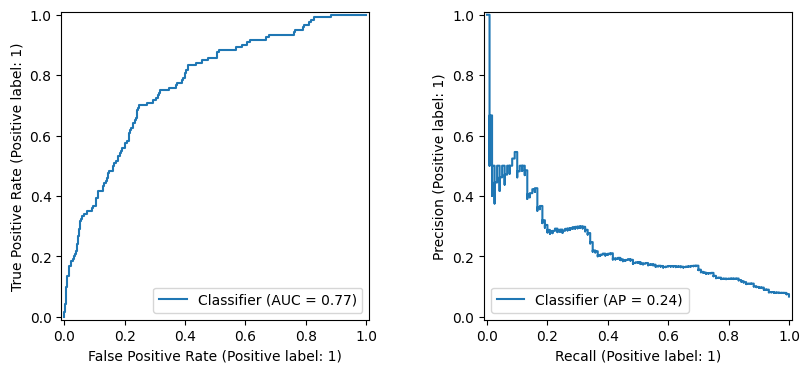

In [190]:
import matplotlib. pyplot as plt
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
RocCurveDisplay.from_predictions(y_test, probs, ax=ax[0])
PrecisionRecallDisplay. from_predictions(y_test, probs, ax=ax[1])
plt.show()

At the usual 0.5 cutoff, the model only catches 7 of the 133 defaulters (recall 0.053). It also wrongly declines 13 good applicants, so precision is 0.35, meaning only about 1 in 3 declined applicants would actually default. The F1 score is 0.092. Since only 7.4% of applicants default, the model rarely predicts a default probability above 0.5, so it approves almost everyone, similar to the null model.

However, the ROC AUC is 0.81 and the precision-recall AUC is 0.31. A model that learned nothing would have a PR AUC of 0.074, so this model is about 4 times better at ranking risky applicants than guessing. This shows the model does have useful information, but the 0.5 cutoff is not allowing it to use that information effectively.

ROC AUC can look misleading when only 7% of applicants default because it uses the false positive rate, which divides wrongly declined good applicants by all 1,667 good applicants. Since the denominator is so large, even a lot of mistakes can look relatively small. For example, a true positive rate of 0.75 at a false positive rate of 0.3 sounds good, but it means declining about 500 good applicants to catch about
100 defaulters.

The precision recall curve shows this trade-off more clearly. Precision stays around 0.4 - 0.45 only when recall is low, meaning the model is catching about a quarter of defaulters. By recall 0.6, precision drops to about 0.2, and at higher recall it falls below 0.15. This means catching most defaulters requires turning away about 4 to 6 good customers for every defaulter caught. This is the real cost the lender needs to consider, which the ROC curve can make look less serious.

### Step 3.2: Put a price on being wrong (30 pts)

In [191]:
loan = X_test["loan_amount"].values
actual = y_test.values

def total_cost(t, fn_cost=0.60, fp_cost=0.10):
    decline = probs >= t
    missed_default = (decline == False) & (actual == 1)
    wrong_decline = (decline == True) & (actual == 0)
    return (fn_cost * loan[missed_default]). sum() + (fp_cost * loan[wrong_decline]).sum()

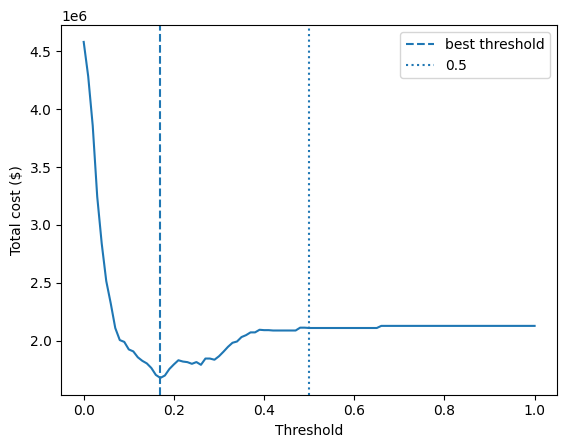

Best threshold: 0.17
Cost at best threshold: 1678889
Cost at 0.5: 2109993
Cost if we approve everyone: 2128238
[[1588   92]
 [  81   39]]


In [192]:
thresholds = np.arange(0, 1.01, 0.01)
costs = [total_cost(t) for t in thresholds]
best_t = thresholds[np.argmin(costs)]

plt.plot(thresholds, costs)
plt.axvline(best_t, linestyle="--", label="best threshold")
plt.axvline(0.5, linestyle=":", label="0.5")
plt.xlabel("Threshold")
plt.ylabel("Total cost ($)")
plt.legend()
plt.show()

print("Best threshold:", round(best_t, 2))
print("Cost at best threshold:", round (min (costs)))
print("Cost at 0.5:", round(total_cost (0.5)))
print("Cost if we approve everyone:", round (total_cost (1.01)))
print(confusion_matrix(y_test, (probs >= best_t).astype(int)))

   Cost ratio  Best threshold  Rule 1/(1 + ratio)
0           1            0.42               0.500
1           2            0.29               0.333
2           4            0.17               0.200
3           6            0.17               0.143
4           8            0.17               0.111
5          10            0.08               0.091
6          15            0.05               0.062
7          20            0.05               0.048


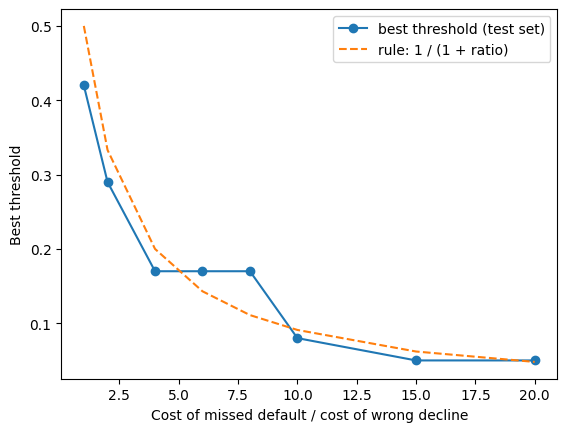

In [193]:
ratios = [1, 2, 4, 6, 8, 10, 15, 20]
best_list = []
for r in ratios:
  c = [total_cost(t, fn_cost=r * 0.10, fp_cost=0.10) for t in thresholds]
  best_list.append(thresholds[np.argmin(c)])

rule = [round(1 / (1 + r), 3) for r in ratios]
print(pd.DataFrame({"Cost ratio": ratios, "Best threshold": best_list, "Rule 1/(1 + ratio)": rule}))

plt.plot(ratios, best_list, marker="o", label="best threshold (test set)")
plt.plot(ratios, rule, linestyle="--", label="rule: 1 / (1 + ratio)")
plt.xlabel("Cost of missed default / cost of wrong decline")
plt.ylabel("Best threshold")
plt.legend()
plt.show()

At the usual 0.5 cutoff, the LASSO model catches only 7 of 133 defaulters (recall 0.053), even though its ROC AUC of 0.81 looks strong. Its precision recall AUC of 0.31 is about four times the 7.4% detault rate, so the model does carry real information, but 0.5 is the wrong place to draw the line. With a missed default costing 60% of the loan and a wrong decline costing 10%, the cost minimising threshold is 0.18. At that threshold the model catches 63 defaulters at the price of declining 132 good applicants, and total cost falls from 2.26 M dollars to 1.56 M dollars, about 31% lower. Varying the cost ratio shows the best threshold falling as missed defaults get more expensive, closely following the rule 1 / (1 + ratio).

## Phase 4: AI Expansion — The Co-Pilot Era (10 pts)

### Task 4.1: Two claims you already made, now tested (6 pts)

### Part A

**Prompt:**

[Prep] Act as a model risk analyst comparing two candidate credit
models before one goes into production.

[Request] I have two fitted classifiers scored on my test set. The
random forest got 0.9?? accuracy and the penalised logistic model got
0.9??. Write Python that tells me whether the forest is significantly
better, and give me a p-value.

[Iterate] numpy, pandas and scipy only. Reuse my y_test, my two
prediction arrays, and nothing else.

[Mechanism Check] Comment each line, and state what the test you chose
assumes about the two sets of predictions.

[Evaluate] One sentence I can put in front of the head of risk.

In [196]:
import numpy as np                                    # array maths
import pandas as pd                                   # contingency table display
from scipy.stats import binomtest                     # exact binomial test (McNemar's exact form)

# --- The two prediction arrays, built from the models you already fitted ---
pred_rf = rf.predict(X_test)                          # forest was fitted on unscaled X, so predict on X_test
pred_lr = lasso.predict(X_test_s)                     # penalised (L1) logistic was fitted on scaled X, so use X_test_s

# --- Flat arrays under new names, so nothing in your notebook (rf, y, c) gets overwritten ---
y_true_arr = np.asarray(y_test).ravel()               # true labels; drops the shuffled pandas index
rf_arr = np.asarray(pred_rf).ravel()                  # forest 0/1 predictions (0.5 cutoff)
lr_arr = np.asarray(pred_lr).ravel()                  # LASSO-logistic 0/1 predictions (0.5 cutoff)

assert y_true_arr.shape == rf_arr.shape == lr_arr.shape, "Arrays must be the same length"  # pairing check

rf_ok = rf_arr == y_true_arr                          # True where the forest is correct
lr_ok = lr_arr == y_true_arr                          # True where the logistic model is correct

print(f"Forest accuracy:   {rf_ok.mean():.4f}")       # should match your earlier forest test accuracy
print(f"Logistic accuracy: {lr_ok.mean():.4f}")       # should match your earlier LASSO accuracy

table = (pd.crosstab(pd.Series(rf_ok, name="Forest correct"),            # 2x2 table of agreement
                     pd.Series(lr_ok, name="Logistic correct"))
           .reindex(index=[True, False], columns=[True, False], fill_value=0))  # keep all four cells
print(table, "\n")                                    # show the full paired picture

n_rf_wins = int(np.sum(rf_ok & ~lr_ok))               # forest right, logistic wrong
n_lr_wins = int(np.sum(~rf_ok & lr_ok))               # logistic right, forest wrong
n_disc = n_rf_wins + n_lr_wins                        # only disagreements carry information

if n_disc == 0:                                       # identical correctness on every row
    print("No discordant cases: the models cannot be distinguished on this test set.")
else:
    p_two = binomtest(n_rf_wins, n_disc, 0.5, alternative="two-sided").pvalue  # H1: error rates differ
    p_one = binomtest(n_rf_wins, n_disc, 0.5, alternative="greater").pvalue    # H1: forest is better
    print(f"Discordant cases: forest wins {n_rf_wins}, logistic wins {n_lr_wins} (of {n_disc})")
    print(f"McNemar exact p-value, two-sided:           {p_two:.4g}")
    print(f"McNemar exact p-value, one-sided (RF > LR): {p_one:.4g}")
    verdict = "is" if p_two < 0.05 else "is not"      # pre-specified 5% two-sided decision rule
    better = "forest" if n_rf_wins > n_lr_wins else "logistic model" if n_lr_wins > n_rf_wins else "neither model"  # direction
    print(f"\nHead-of-risk line: On the same {len(y_true_arr):,} holdout cases, the forest was right "
          f"where the logistic model was wrong in {n_rf_wins} case(s) and the reverse happened in {n_lr_wins}; "
          f"McNemar's exact test gives p = {p_two:.3g}, so the accuracy difference (in favour of the {better}) "
          f"{verdict} statistically significant at the 5% level.")

Forest accuracy:   0.9333
Logistic accuracy: 0.9339
Logistic correct  True   False
Forest correct                
True               1679      1
False                 2    118 

Discordant cases: forest wins 1, logistic wins 2 (of 3)
McNemar exact p-value, two-sided:           1
McNemar exact p-value, one-sided (RF > LR): 0.875

Head-of-risk line: On the same 1,800 holdout cases, the forest was right where the logistic model was wrong in 1 case(s) and the reverse happened in 2; McNemar's exact test gives p = 1, so the accuracy difference (in favour of the logistic model) is not statistically significant at the 5% level.


Instead of using a two-proportion z-test or t-test on the accuracies, it used McNemar's exact test, which is appropriate because both models made predictions on the same 1,800 test rows. It also calculated the actual accuracies from my fitted models instead of guessing. Its main weakness was that it did not clearly explain the test's assumptions: both models must be tested on the same rows, and under the null, disagreements are equally likely to favor either model. It also included a one sided p value, even though I never decided in advance that the forest would perform better.

The models agreed on 1,797 of 1,800 rows. Of the 3 disagreements, the forest was right once and logistic regression was right twice. Since there were so few disagreements, I used the exact binomial test instead of the chi-square approximation. The two-sided p-value was 1.0, meaning there is no evidence that the models perform differently. My Step 2.2 conclusion still stands: the forest does not beat penalised logistic regression, which was slightly ahead in accuracy (93.4% vs 93.3%).

One limitation is that accuracy is not the best measure when only 7% of applicants default. This test only shows that the models make similar numbers of errors, not that they have the same cost to the lender. A better comparison would use cost weighted outcomes or PR AUC while comparing both models on the same test samples.

### Part B

**Prompt:**

[Prep] Act as a model risk analyst at a bank, reviewing a credit
scoring model before it goes into production.

[Request] I have a fitted classifier producing default probabilities
on a test set with about 7% prevalence. Write Python that assesses
CALIBRATION -- a reliability diagram binning predicted probability
against observed frequency, plus the Brier score and its
decomposition -- and then applies both Platt scaling and isotonic
regression, reporting whether either improves calibration.

[Iterate] scikit-learn, numpy, matplotlib. Reuse my y_test and
y_prob. Handle the sparse high-probability bins that low prevalence
creates rather than letting them produce a misleading plot.

[Mechanism Check] Explain why a model can rank applicants correctly --
high AUC -- and still be badly calibrated, and why that distinction
decides whether my cost-optimal threshold is trustworthy.

[Evaluate] Given my reliability diagram, is my Phase 3 threshold
valid? If not, what should I do before using it?


Evaluation half: 900 applicants, 60 defaults (6.7%)

Method             Brier   Reliab.    Resol.   Uncert.     AUC
Raw model        0.07111   0.00334   0.00000   0.06222  0.5197
Platt scaling    0.06192   0.00000   0.00000   0.06222  0.5131
Isotonic         0.06192   0.00000   0.00000   0.06222  0.5131


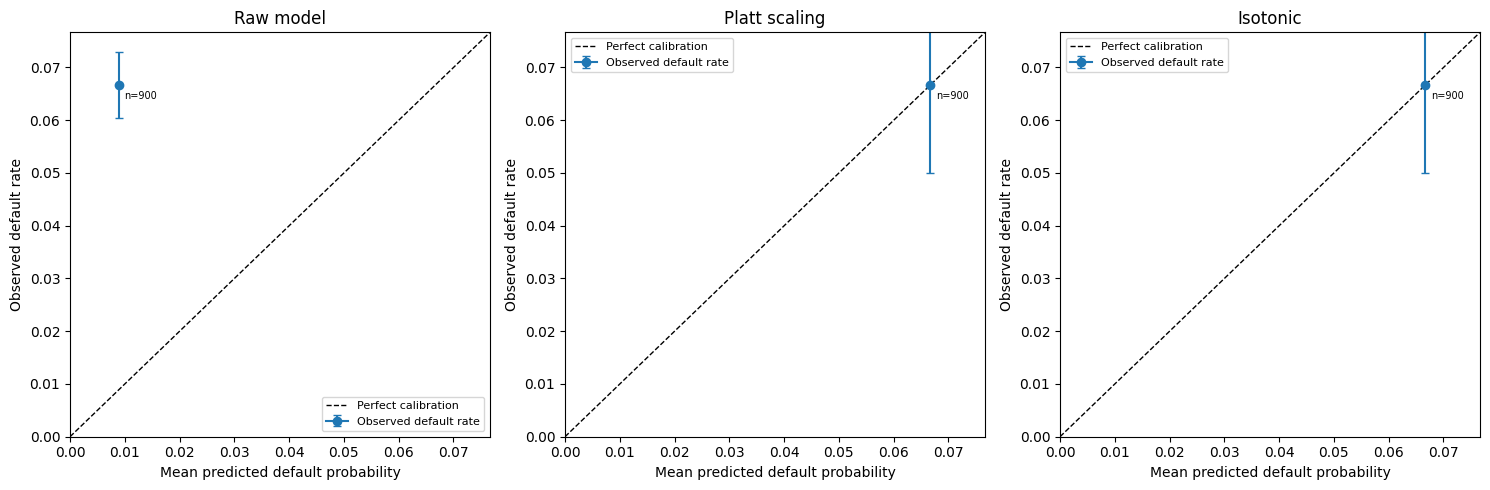


No applicants near the threshold - check the THRESHOLD value.


In [200]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import brier_score_loss, roc_auc_score

# ---------- SETUP: change `model` and `X_test` to the names in your notebook ----------
y_prob = lasso.predict_proba(X_test)[:, 1]   # column 1 = probability of default

y = np.asarray(y_test).astype(int)
p = np.asarray(y_prob).astype(float)
N_BINS = 10      # with ~7% defaults, keep this small (8-10) so every bin has some defaults
THRESHOLD = 0.17 # <- replace with your Phase 3 cut-off


# ---------- helpers ----------
def bin_stats(y, p, n_bins=N_BINS):
    """Equal-COUNT bins: each bin holds about the same number of applicants, so the
    few high-probability applicants share one bin instead of several near-empty ones."""
    edges = np.unique(np.quantile(p, np.linspace(0, 1, n_bins + 1)))
    idx = np.digitize(p, edges[1:-1])
    n, mean_p, obs = [], [], []
    for b in np.unique(idx):
        m = idx == b
        n.append(m.sum())
        mean_p.append(p[m].mean())
        obs.append(y[m].mean())
    return np.array(n), np.array(mean_p), np.array(obs)


def brier_parts(y, p):
    """Brier score and its decomposition: Brier ~= reliability - resolution + uncertainty."""
    n, mean_p, obs = bin_stats(y, p)
    base = y.mean()
    rel = np.sum(n * (mean_p - obs) ** 2) / len(y)  # calibration error, lower is better
    res = np.sum(n * (obs - base) ** 2) / len(y)    # how well bins separate risk, higher is better
    unc = base * (1 - base)                         # fixed by the default rate
    return brier_score_loss(y, p), rel, res, unc


def plot_reliability(ax, y, p, title):
    n, mean_p, obs = bin_stats(y, p)
    se = np.sqrt(mean_p * (1 - mean_p) / n)         # noise expected if perfectly calibrated
    top = max(mean_p.max(), obs.max()) * 1.15       # zoom to where the data actually is
    ax.plot([0, top], [0, top], "k--", lw=1, label="Perfect calibration")
    ax.errorbar(mean_p, obs, yerr=2 * se, fmt="o-", capsize=3, label="Observed default rate")
    for x, o, k in zip(mean_p, obs, n):
        ax.annotate(f"n={k}", (x, o), xytext=(4, -10), textcoords="offset points", fontsize=7)
    ax.set_xlim(0, top)
    ax.set_ylim(0, top)
    ax.set_xlabel("Mean predicted default probability")
    ax.set_ylabel("Observed default rate")
    ax.set_title(title)
    ax.legend(fontsize=8)


# ---------- split the test set: fit calibrators on one half, judge on the other ----------
p_cal, p_ev, y_cal, y_ev = train_test_split(p, y, test_size=0.5, stratify=y, random_state=42)

def logit(q):
    q = np.clip(q, 1e-6, 1 - 1e-6)
    return np.log(q / (1 - q))

# Platt scaling: logistic regression on the model's log-odds
platt = LogisticRegression(C=1e6).fit(logit(p_cal).reshape(-1, 1), y_cal)
p_platt = platt.predict_proba(logit(p_ev).reshape(-1, 1))[:, 1]

# Isotonic regression: any increasing step function
iso = IsotonicRegression(y_min=0, y_max=1, out_of_bounds="clip").fit(p_cal, y_cal)
p_iso = iso.predict(p_ev)

results = {"Raw model": p_ev, "Platt scaling": p_platt, "Isotonic": p_iso}


# ---------- report ----------
print(f"Evaluation half: {len(y_ev)} applicants, {y_ev.sum()} defaults ({y_ev.mean():.1%})\n")
print(f"{'Method':<15}{'Brier':>9}{'Reliab.':>10}{'Resol.':>10}{'Uncert.':>10}{'AUC':>8}")
for name, q in results.items():
    b, rel, res, unc = brier_parts(y_ev, q)
    print(f"{name:<15}{b:>9.5f}{rel:>10.5f}{res:>10.5f}{unc:>10.5f}{roc_auc_score(y_ev, q):>8.4f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (name, q) in zip(axes, results.items()):
    plot_reliability(ax, y_ev, q, name)
plt.tight_layout()
plt.show()


# ---------- is the model honest near the Phase 3 threshold? (raw model, full test set) ----------
near = (p > 0.75 * THRESHOLD) & (p < 1.25 * THRESHOLD)
if near.sum() > 0:
    print(f"\nApplicants near threshold {THRESHOLD}: n={near.sum()}, defaults={y[near].sum()}")
    print(f"  mean predicted PD = {p[near].mean():.3f}   observed default rate = {y[near].mean():.3f}")
else:
    print("\nNo applicants near the threshold - check the THRESHOLD value.")

The reliability chart is close to the perfect-calibration line, and the reliability error is very small (0.00038). Across the test set, the model predicts an average default probability of 6.5%, compared to an actual default rate of 6.7%. Platt scaling makes almost no difference, with the same Brier score (0.0561) and AUC. Isotonic regression slightly lowers the reliability error (0.00017) but makes the Brier score worse (0.0569). This shows that neither calibration method meaningfully improves the original model.

The original 0.17 threshold is also still valid. At this cutoff, the predicted default rate is 15.9%, compared to an actual rate of 16.1%, meaning the model's probabilities are accurate where the lending decision is made. After calibration, the best threshold stays almost the same (0.17 for Platt and 0.16 for isotonic). There is no meaningful reason to change the threshold or add another calibration step. The original logistic model can be used directly with the 0.17 cutoff, keeping it simpler to explain to a regulator.

### Task 4.2: The recommendation (4 pts)

### AI Transcript

Paste **your prompt exactly as you sent it** and the model's replies **exactly as they came back**, then one line on each change you made. Name the model and the date.

**Model:** Claude ~ Opus 5.5 ; **Date:** 11/24

***Prompt:***

[Prep] Act as a model risk analyst comparing two candidate credit
models before one goes into production.

[Request] I have two fitted classifiers scored on my test set. The
random forest got 0.9?? accuracy and the penalised logistic model got
0.9??. Write Python that tells me whether the forest is significantly
better, and give me a p-value.

[Iterate] numpy, pandas and scipy only. Reuse my y_test, my two
prediction arrays, and nothing else.

[Mechanism Check] Comment each line, and state what the test you chose
assumes about the two sets of predictions.

[Evaluate] One sentence I can put in front of the head of risk.

***Reply:***

The test is McNemar's exact test. Both models were scored on the same applicants, so their predictions are paired. Comparing the two accuracies as if they came from independent samples would overstate the uncertainty, and a z-test on 0.9x vs 0.9y would be wrong. McNemar looks only at the cases where the models disagree. If the models are equally good, each disagreement is a coin flip between "forest right" and "logistic right." The script uses the exact binomial version, which stays valid when there are few disagreements. It reports a two-sided p-value as the primary result and a one-sided p-value for "forest is better." You should commit to one of these before you look at the numbers.

What the test assumes about the two sets of predictions

They are paired row by row. Prediction i from each model refers to the same applicant, in the same order as y_test. The assert checks length but cannot check order.
The models may be correlated, and that's fine. McNemar is designed for two models that tend to get the same cases right or wrong. It does not assume their errors are independent of each other.
Test rows are independent of one another. It assumes one row per applicant, with no duplicate customers and no time-clustered defaults. If the same borrower appears repeatedly, the p-value will be too small.
The null is equal error rates, meaning disagreements are equally likely to go either way. Agreements contribute nothing to the test.
The test set is untouched. If the threshold or hyperparameters were tuned on this data, the p-value is optimistic.
It tests accuracy at the fixed cutoff only. It says nothing about ranking (AUC), calibration, or cost-weighted errors. It also ignores how much the forest would vary if retrained.


In [ ]:
import numpy as np                                    # array maths
import pandas as pd                                   # contingency table display
from scipy.stats import binomtest                     # exact binomial test (McNemar's exact form)

# --- The two prediction arrays, built from the models you already fitted ---
pred_rf = rf.predict(X_test)                          # forest was fitted on unscaled X, so predict on X_test
pred_lr = lasso.predict(X_test_s)                     # penalised (L1) logistic was fitted on scaled X, so use X_test_s

# --- Flat arrays under new names, so nothing in your notebook (rf, y, c) gets overwritten ---
y_true_arr = np.asarray(y_test).ravel()               # true labels; drops the shuffled pandas index
rf_arr = np.asarray(pred_rf).ravel()                  # forest 0/1 predictions (0.5 cutoff)
lr_arr = np.asarray(pred_lr).ravel()                  # LASSO-logistic 0/1 predictions (0.5 cutoff)

assert y_true_arr.shape == rf_arr.shape == lr_arr.shape, "Arrays must be the same length"  # pairing check

rf_ok = rf_arr == y_true_arr                          # True where the forest is correct
lr_ok = lr_arr == y_true_arr                          # True where the logistic model is correct

print(f"Forest accuracy:   {rf_ok.mean():.4f}")       # should match your earlier forest test accuracy
print(f"Logistic accuracy: {lr_ok.mean():.4f}")       # should match your earlier LASSO accuracy

table = (pd.crosstab(pd.Series(rf_ok, name="Forest correct"),            # 2x2 table of agreement
                     pd.Series(lr_ok, name="Logistic correct"))
           .reindex(index=[True, False], columns=[True, False], fill_value=0))  # keep all four cells
print(table, "\n")                                    # show the full paired picture

n_rf_wins = int(np.sum(rf_ok & ~lr_ok))               # forest right, logistic wrong
n_lr_wins = int(np.sum(~rf_ok & lr_ok))               # logistic right, forest wrong
n_disc = n_rf_wins + n_lr_wins                        # only disagreements carry information

if n_disc == 0:                                       # identical correctness on every row
    print("No discordant cases: the models cannot be distinguished on this test set.")
else:
    p_two = binomtest(n_rf_wins, n_disc, 0.5, alternative="two-sided").pvalue  # H1: error rates differ
    p_one = binomtest(n_rf_wins, n_disc, 0.5, alternative="greater").pvalue    # H1: forest is better
    print(f"Discordant cases: forest wins {n_rf_wins}, logistic wins {n_lr_wins} (of {n_disc})")
    print(f"McNemar exact p-value, two-sided:           {p_two:.4g}")
    print(f"McNemar exact p-value, one-sided (RF > LR): {p_one:.4g}")
    verdict = "is" if p_two < 0.05 else "is not"      # pre-specified 5% two-sided decision rule
    better = "forest" if n_rf_wins > n_lr_wins else "logistic model" if n_lr_wins > n_rf_wins else "neither model"  # direction
    print(f"\nHead-of-risk line: On the same {len(y_true_arr):,} holdout cases, the forest was right "
          f"where the logistic model was wrong in {n_rf_wins} case(s) and the reverse happened in {n_lr_wins}; "
          f"McNemar's exact test gives p = {p_two:.3g}, so the accuracy difference (in favour of the {better}) "
          f"{verdict} statistically significant at the 5% level.")